# Project 2 Starter Code
---
<div class="alert alert-block alert-success" style="color:black;">
<b>To Begin:</b> Use this <b>Project_2_Starter_Code.ipynb</b> if you choose to develop your project. The following are just some potential pointers to help you get started. <b>Note:</b> The submission is a report so a fully developed code solution is not needed.
    
<br><br>
<b>When Finished:</b> When you have completed your work, submit a 4 to 5 page Microsoft Word document with double spacing, 12-point Times New Roman font, and one-inch margin. Sources should be cited according to APA style.
</div>

<div class="alert alert-block alert-danger" style="color:black;">
<b>GPU/CUDA/Memory Warnings/Errors:</b> You may receive some errors referencing that GPUs will not be used, CUDA could not be found, or free system memory allocation errors. These and a few others, are standard errors that can be ignored here as they are environment based.<br><br>
<b>Example messages:</b>
    <ul>
        <li>Could not find cuda drivers on your machine, GPU will not be used.</li>
        <li>Please check linkage and avoid linking the same target more than once.</li>
        <li>E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)</li>
        <li>Allocation of ######## exceeds 10% of free system memory</li>
    </ul>
</div>

In [1]:
# Potential Libraries for Project 2

In [6]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
# Seeding and Reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seed(42)
AUTOTUNE = tf.data.AUTOTUNE

In [15]:
# POSSIBLE Configuration setup 

#DATA_DIR = ""
IMG_SIZE = (28, 28, 1)   # Fashion-MNIST native dimensions
BATCH_SIZE = 32
EPOCHS = 3
MAX_TOKENS = 10000
MAX_LEN = 64
EMBED_DIM = 64
NUM_CLASSES = 4

CLASS_NAMES = ["Normal", "Accident", "Road Hazard", "Severe Congestion"]

### TODO: Choose a dataset and preprocess as needed

In [16]:
# You may want to have separate functions for image & text
def load_image_dataset():
    (x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
    # Normalize pixel values and add channel dimension
    x_train = np.expand_dims(x_train.astype("float32") / 255.0, -1)
    x_test = np.expand_dims(x_test.astype("float32") / 255.0, -1)
    return (x_train, y_train), (x_test, y_test)


def load_text_dataset():
    train_url = "https://raw.githubusercontent.com/mhjabreel/CharCnn_Keras/master/data/ag_news_csv/train.csv"
    test_url = "https://raw.githubusercontent.com/mhjabreel/CharCnn_Keras/master/data/ag_news_csv/test.csv"
    
    ag_train = pd.read_csv(train_url, names=["label", "title", "description"])
    ag_test = pd.read_csv(test_url, names=["label", "title", "description"])
    
    # Adjust labels from 1-4 to 0-3 and combine title + description
    ag_train["label"] = ag_train["label"] - 1
    ag_test["label"] = ag_test["label"] - 1
    ag_train["text"] = ag_train["title"] + " " + ag_train["description"]
    ag_test["text"] = ag_test["title"] + " " + ag_test["description"]
    
    return ag_train, ag_test

def load_dataset():
    (img_train, img_y_train), (img_test, img_y_test) = load_image_dataset()
    txt_train, txt_test = load_text_dataset()
    
    # Helper to pair images and text 1-to-1 by class (0 to 3)
    def pair_modalities(imgs, img_labels, texts, text_labels, samples_per_class=1000):
        p_imgs, p_texts, p_labels = [], [], []
        for cls in range(NUM_CLASSES):
            c_imgs = imgs[img_labels == cls][:samples_per_class]
            c_texts = texts[text_labels == cls].values[:samples_per_class]
            n = min(len(c_imgs), len(c_texts))
            p_imgs.append(c_imgs[:n])
            p_texts.extend(c_texts[:n])
            p_labels.extend([cls] * n)
            
        p_imgs = np.concatenate(p_imgs, axis=0)
        p_texts = np.array(p_texts)
        p_labels = np.array(p_labels)
        
        idx = np.random.permutation(len(p_labels))
        return p_imgs[idx], p_texts[idx], p_labels[idx]

    X_img_train, X_txt_train, y_train = pair_modalities(img_train, img_y_train, txt_train["text"], txt_train["label"], 1000)
    X_img_test, X_txt_test, y_test = pair_modalities(img_test, img_y_test, txt_test["text"], txt_test["label"], 250)
    
    return {
        "train_images": X_img_train, "train_texts": X_txt_train, "train_labels": y_train,
        "test_images": X_img_test, "test_texts": X_txt_test, "test_labels": y_test
    }

# Execute dataset loading
data = load_dataset()

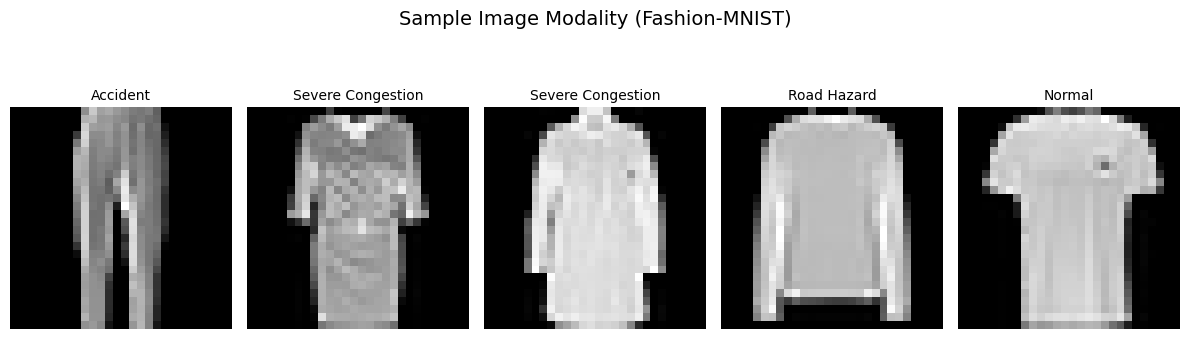

Sample Text Modality (AG News)

Label: [Accident]
Text: Chicago White Sox Team Report - August 18 (Sports Network) - Jose Contreras tries to stay perfect in a Chicago uniform this evening when the White Sox...

Label: [Severe Congestion]
Text: Apple Introduces Production Suite Production Suite, essential software suite for film and video that delivers real-time production tools in one compre...

Label: [Severe Congestion]
Text: Teleportation goes long distance Physicists teleport particles of light a distance of 600m across the River Danube in Austria, the journal Nature repo...

Label: [Road Hazard]
Text: U.S. Execs Plan More Hiring - Survey (Reuters) Reuters - Most senior executives at large U.S.\companies plan to increase hiring and investments over t...

Label: [Normal]
Text: German welfare rallies escalate Thousands of people have marched through cities across Germany in renewed protests against welfare cuts. ...


In [17]:
# Image Samples
plt.figure(figsize=(12, 4))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    img = data["train_images"][i].squeeze()  # Remove channel dimension for grayscale display
    label_idx = data["train_labels"][i]
    plt.imshow(img, cmap="gray")
    plt.title(f"{CLASS_NAMES[label_idx]}", fontsize=10)
    plt.axis("off")
plt.suptitle("Sample Image Modality (Fashion-MNIST)", fontsize=14)
plt.tight_layout()
plt.show()

# Text Samples
print("Sample Text Modality (AG News)")
for i in range(5):
    txt = data["train_texts"][i]
    label_idx = data["train_labels"][i]
    print(f"\nLabel: [{CLASS_NAMES[label_idx]}]")
    print(f"Text: {txt[:150]}...")  # Print first 150 characters of the sample

### TODO: Build Multimodal Pipelines

In [18]:
# You may want to create different pipelines for image and text
def make_pipeline(images, texts, labels, batch_size=32, is_training=True):
    dataset = tf.data.Dataset.from_tensor_slices(((images, texts), labels))
    if is_training:
        dataset = dataset.shuffle(buffer_size=1024)
    dataset = dataset.batch(batch_size).prefetch(AUTOTUNE)
    return dataset

### TODO: Create Modalities Stream

In [19]:
def modalities():
    train_ds = make_pipeline(
        data["train_images"], data["train_texts"], data["train_labels"], 
        batch_size=BATCH_SIZE, is_training=True
    )
    test_ds = make_pipeline(
        data["test_images"], data["test_texts"], data["test_labels"], 
        batch_size=BATCH_SIZE, is_training=False
    )
    return train_ds, test_ds

train_ds, test_ds = modalities()

### TODO: Build Multimodal model

In [20]:
# Initialize and adapt the text vectorizer first
vectorizer = layers.TextVectorization(max_tokens=MAX_TOKENS, output_sequence_length=MAX_LEN)
vectorizer.adapt(data["train_texts"])

def build_multimodal_model():
    # Vision Branch
    image_input = keras.Input(shape=IMG_SIZE, name="image_input")
    v = layers.Conv2D(32, (3, 3), activation="relu")(image_input)
    v = layers.MaxPooling2D((2, 2))(v)
    v = layers.Conv2D(64, (3, 3), activation="relu")(v)
    v = layers.GlobalAveragePooling2D()(v)
    v = layers.Dense(64, activation="relu")(v)

    # Text Branch
    text_input = keras.Input(shape=(1,), dtype=tf.string, name="text_input")
    t = vectorizer(text_input)
    t = layers.Embedding(MAX_TOKENS, EMBED_DIM)(t)
    t = layers.GlobalAveragePooling1D()(t)
    t = layers.Dense(64, activation="relu")(t)

    # Multimodal Fusion
    fused = layers.Concatenate()([v, t])
    fused = layers.Dense(64, activation="relu")(fused)
    fused = layers.Dropout(0.3)(fused)
    output = layers.Dense(NUM_CLASSES, activation="softmax", name="output")(fused)

    model = keras.Model(inputs=[image_input, text_input], outputs=output)
    return model

model = build_multimodal_model()
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 26, 26,    │        320 │ image_input[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_input          │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 13, 13,    │          0 │ conv2d_4[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization… │ (None, 64)        │          0 │ text_input[0][0]  │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 11, 11,    │     18,496 │ max_pooling2d_2[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 64, 64)    │    640,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ conv2d_5[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ embedding_1[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 64)        │      4,160 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 64)        │      4,160 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 128)       │          0 │ dense_4[0][0],    │
│ (Concatenate)       │                   │            │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 64)        │      8,256 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, 4)         │        260 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 675,652 (2.58 MB)

 Trainable params: 675,652 (2.58 MB)

 Non-trainable params: 0 (0.00 B)

### TODO: Compile and Train your model

In [21]:
# Compile and train model as need be
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=EPOCHS
)

Epoch 1/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.5460 - loss: 1.0670 - val_accuracy: 0.8240 - val_loss: 0.5928
Epoch 2/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.8662 - loss: 0.4245 - val_accuracy: 0.8840 - val_loss: 0.3452
Epoch 3/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.9290 - loss: 0.2280 - val_accuracy: 0.9070 - val_loss: 0.2533


### TODO: Plot Visualization if needed

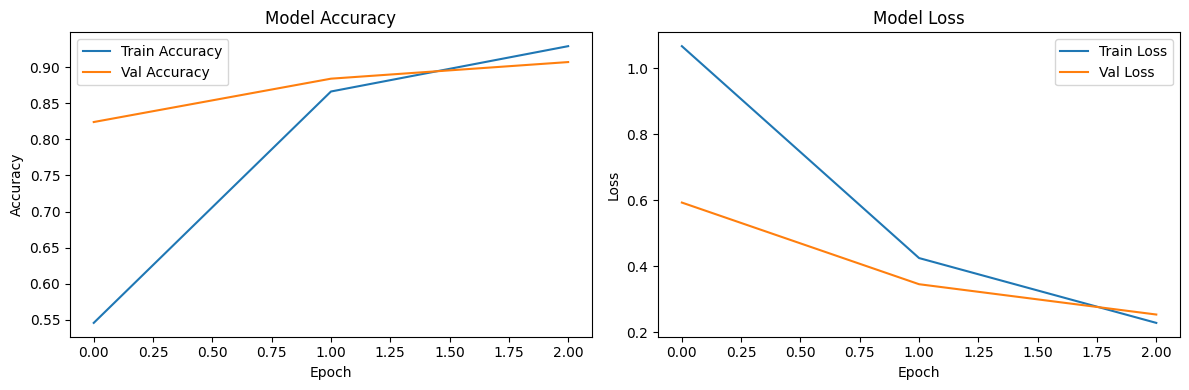

In [22]:
def plot_history(history):
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 2, 1)
    plt.plot(history.history["accuracy"], label="Train Accuracy")
    plt.plot(history.history["val_accuracy"], label="Val Accuracy")
    plt.title("Model Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.plot(history.history["loss"], label="Train Loss")
    plt.plot(history.history["val_loss"], label="Val Loss")
    plt.title("Model Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    
    plt.tight_layout()
    plt.show()

plot_history(history)

### TODO: Evaluate your model

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step

Classification Report:
                   precision    recall  f1-score   support

           Normal       0.92      0.86      0.89       250
         Accident       0.96      0.96      0.96       250
      Road Hazard       0.88      0.92      0.90       250
Severe Congestion       0.86      0.90      0.88       250

         accuracy                           0.91      1000
        macro avg       0.91      0.91      0.91      1000
     weighted avg       0.91      0.91      0.91      1000



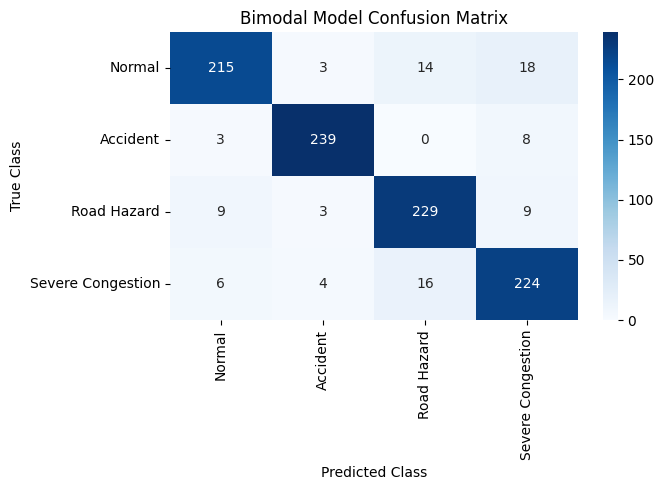

In [23]:
y_pred_probs = model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

print("\nClassification Report:")
print(classification_report(data["test_labels"], y_pred, target_names=CLASS_NAMES))

cm = confusion_matrix(data["test_labels"], y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("Bimodal Model Confusion Matrix")
plt.ylabel("True Class")
plt.xlabel("Predicted Class")
plt.tight_layout()
plt.show()

<div class="alert alert-block alert-success" style="color:black;">
<b>When Finished:</b> When you have completed your work, submit a 4 to 5 page Microsoft Word document with double spacing, 12-point Times New Roman font, and one-inch margin. Sources should be cited according to APA style.
</div>